In [1]:
#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("dataset")
OUTPUT_DIR = Path("output")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

appointments = pd.read_csv(DATA_DIR / "appointments.csv")
patients = pd.read_csv(DATA_DIR / "patients.csv")
doctors = pd.read_csv(DATA_DIR / "doctors.csv")
reminders = pd.read_csv(DATA_DIR / "reminders.csv")
calendar = pd.read_csv(DATA_DIR / "calendar.csv")

datasets = {
    "Appointments": appointments,
    "Patients": patients,
    "Doctors": doctors,
    "Reminders": reminders,
    "Calendar": calendar
}

print("All five datasets loaded successfully!")

All five datasets loaded successfully!


In [3]:
for name, df in datasets.items():
    print(f"\n{name}")
    print("Records:", len(df))
    print("Attributes:", len(df.columns))
    print("Columns:", df.columns.tolist())


Appointments
Records: 1201
Attributes: 7
Columns: ['appointment_id', 'patient_id', 'doctor_id', 'appointment_date', 'booking_date', 'department', 'status']

Patients
Records: 250
Attributes: 4
Columns: ['patient_id', 'age_group', 'locality', 'visit_history']

Doctors
Records: 15
Attributes: 5
Columns: ['doctor_id', 'doctor_name', 'specialty', 'clinic_schedule', 'available_hours_per_week']

Reminders
Records: 964
Attributes: 5
Columns: ['reminder_id', 'appointment_id', 'reminder_type', 'sent_status', 'response']

Calendar
Records: 365
Attributes: 4
Columns: ['date', 'weekday', 'is_holiday', 'season']


In [4]:
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    df.info()


--- Appointments ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1201 entries, 0 to 1200
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   appointment_id    1201 non-null   object
 1   patient_id        1201 non-null   object
 2   doctor_id         1201 non-null   object
 3   appointment_date  1201 non-null   object
 4   booking_date      1201 non-null   object
 5   department        1201 non-null   object
 6   status            1199 non-null   object
dtypes: object(7)
memory usage: 65.8+ KB

--- Patients ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   patient_id     250 non-null    object
 1   age_group      250 non-null    object
 2   locality       250 non-null    object
 3   visit_history  250 non-null    object
dtypes: object(4)
memory usage: 7.9+ 

In [5]:
for name, df in datasets.items():
    print(f"\n--- {name}: Missing Values ---")
    missing = pd.DataFrame({
        "Missing_Count": df.isna().sum(),
        "Missing_Percentage": (df.isna().mean() * 100).round(2)
    })
    display(missing[missing["Missing_Count"] > 0])


--- Appointments: Missing Values ---


,Missing_Count,Missing_Percentage
status,2,0.17



--- Patients: Missing Values ---


,Missing_Count,Missing_Percentage



--- Doctors: Missing Values ---


,Missing_Count,Missing_Percentage



--- Reminders: Missing Values ---


,Missing_Count,Missing_Percentage
sent_status,1,0.10
response,232,24.07



--- Calendar: Missing Values ---


,Missing_Count,Missing_Percentage


In [ ]:
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} exact duplicate rows"
    )

In [6]:
report = []

for name, df in datasets.items():
    report.append({
        "Dataset": name,
        "Records": len(df),
        "Attributes": len(df.columns),
        "Missing_Cells": int(df.isna().sum().sum()),
        "Duplicate_Rows": int(df.duplicated().sum())
    })

quality_report = pd.DataFrame(report)
display(quality_report)

quality_report.to_csv(
    OUTPUT_DIR / "data_quality_report.csv",
    index=False
)

print("Data quality report saved!")

,Dataset,Records,Attributes,Missing_Cells,Duplicate_Rows
0,Appointments,1201,7,2,1
1,Patients,250,4,0,0
2,Doctors,15,5,0,0
3,Reminders,964,5,233,0
4,Calendar,365,4,0,0


Data quality report saved!


Creating visualizations from actual appointment data...


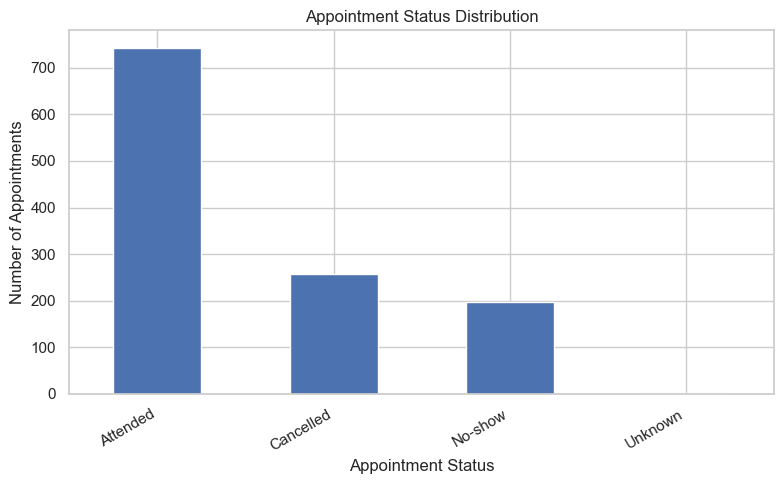

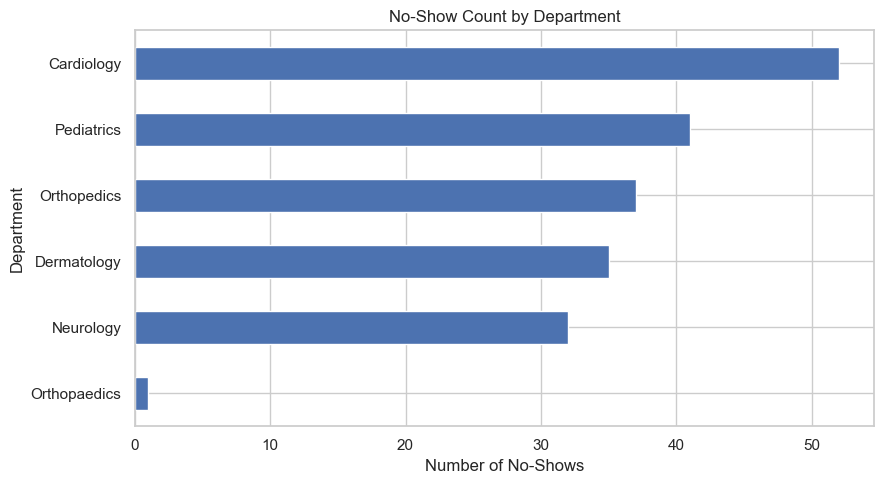

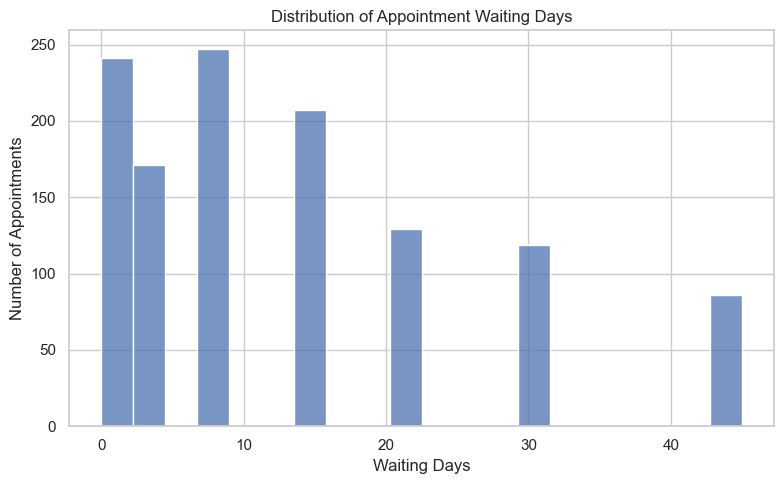

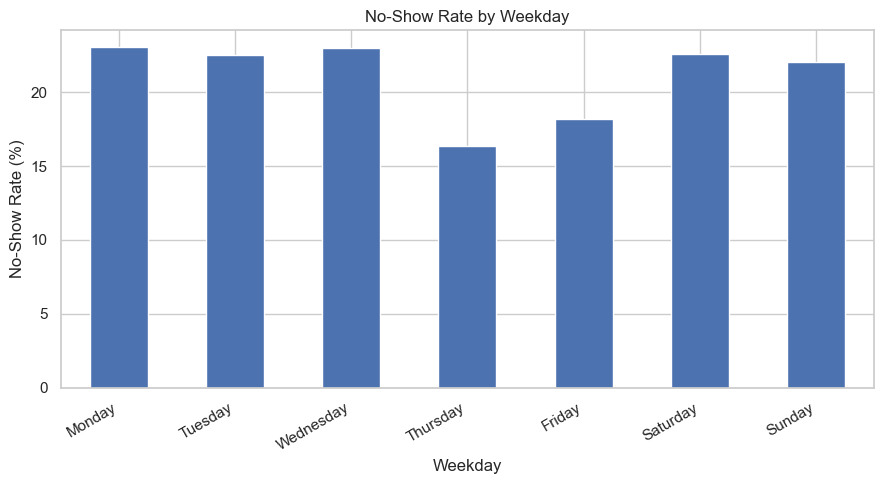


Visualization process completed.
Charts saved in: E:\Hospital_Appointment_Insight\output\charts


In [8]:

# =====================================================
# HOSPITAL APPOINTMENT INSIGHT - VISUALIZATION
# Actual dataset charts for Round 2
# =====================================================

%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Load data if appointments is not already available
if "appointments" not in globals():
    appointments = pd.read_csv(
        Path("dataset") / "appointments.csv"
    )

# Normalize column names for detection
appointments.columns = (
    appointments.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

OUTPUT_DIR = Path("output") / "charts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Creating visualizations from actual appointment data...")

# 1. Appointment status distribution
if "status" in appointments.columns:
    plt.figure(figsize=(8, 5))
    appointments["status"].fillna("Unknown").value_counts().plot(
        kind="bar"
    )
    plt.title("Appointment Status Distribution")
    plt.xlabel("Appointment Status")
    plt.ylabel("Number of Appointments")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "appointment_status.png", dpi=150)
    plt.show()
else:
    print("Status column not found.")

# 2. Department-wise no-show count
if {"department", "status"}.issubset(appointments.columns):
    status = (
        appointments["status"].astype("string")
        .str.strip().str.lower()
        .str.replace(r"[\s_]+", "-", regex=True)
    )

    no_show = status.isin(["no-show", "noshow", "no-showed"])

    department_counts = (
        appointments.loc[no_show, "department"]
        .fillna("Unknown")
        .value_counts()
    )

    if not department_counts.empty:
        plt.figure(figsize=(9, 5))
        department_counts.sort_values().plot(kind="barh")
        plt.title("No-Show Count by Department")
        plt.xlabel("Number of No-Shows")
        plt.ylabel("Department")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "department_no_shows.png", dpi=150)
        plt.show()
    else:
        print("No recognized no-show status values found.")

# 3. Waiting-time distribution
if {"booking_date", "appointment_date"}.issubset(
    appointments.columns
):
    booking = pd.to_datetime(
        appointments["booking_date"], errors="coerce"
    )
    appointment_date = pd.to_datetime(
        appointments["appointment_date"], errors="coerce"
    )

    waiting_days = (appointment_date - booking).dt.days
    valid_waiting = waiting_days[waiting_days >= 0].dropna()

    if not valid_waiting.empty:
        plt.figure(figsize=(8, 5))
        sns.histplot(valid_waiting, bins=20)
        plt.title("Distribution of Appointment Waiting Days")
        plt.xlabel("Waiting Days")
        plt.ylabel("Number of Appointments")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "waiting_days_distribution.png", dpi=150)
        plt.show()
    else:
        print("No valid waiting-day values available.")

# 4. No-show rate by weekday
if {"appointment_date", "status"}.issubset(appointments.columns):
    dates = pd.to_datetime(
        appointments["appointment_date"], errors="coerce"
    )

    status = (
        appointments["status"].astype("string")
        .str.strip().str.lower()
        .str.replace(r"[\s_]+", "-", regex=True)
    )

    attended = status.isin(["attended", "complete", "completed"])
    no_show = status.isin(["no-show", "noshow", "no-showed"])
    known = attended | no_show

    weekday_data = pd.DataFrame({
        "weekday": dates.dt.day_name(),
        "known": known,
        "no_show": no_show
    })

    weekday_data = weekday_data[weekday_data["known"]]

    if not weekday_data.empty:
        weekday_summary = weekday_data.groupby("weekday").agg(
            total=("known", "size"),
            no_shows=("no_show", "sum")
        )

        weekday_summary["no_show_rate"] = (
            weekday_summary["no_shows"]
            / weekday_summary["total"] * 100
        )

        weekday_order = [
            "Monday", "Tuesday", "Wednesday", "Thursday",
            "Friday", "Saturday", "Sunday"
        ]

        weekday_summary = weekday_summary.reindex(
            weekday_order
        ).dropna(subset=["no_show_rate"])

        plt.figure(figsize=(9, 5))
        weekday_summary["no_show_rate"].plot(kind="bar")
        plt.title("No-Show Rate by Weekday")
        plt.xlabel("Weekday")
        plt.ylabel("No-Show Rate (%)")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "weekday_no_show_rate.png", dpi=150)
        plt.show()
    else:
        print("No recognized attendance outcomes for weekday analysis.")

print("\nVisualization process completed.")
print("Charts saved in:", OUTPUT_DIR.resolve())


In [ ]:
# ROUND 2 — FEATURE ENGINEERING & MACHINE LEARNING

## 2.1 Prepare the Cleaned Dataset

## 2.2 Feature Engineering

## 2.3 Select Input Features and Target Variable

## 2.4 Encode Categorical Variables

## 2.5 Split Training and Testing Data

## 2.6 Train the Machine Learning Model

## 2.7 Evaluate Model Performance

## 2.8 Identify Important Features

In [9]:
#before training model
print("Dataset shape:", appointments_clean.shape)
print("\nAvailable columns:")
print(appointments_clean.columns.tolist())

print("\nAppointment status distribution:")
print(appointments_clean["status"].value_counts(dropna=False))

NameError: name 'appointments_clean' is not defined

In [10]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the original appointment dataset
DATA_DIR = Path("dataset")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

appointments = pd.read_csv(DATA_DIR / "appointments.csv")

# Create a separate working copy
appointments_clean = appointments.copy()

# Standardize column names
appointments_clean.columns = (
    appointments_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

# Remove exact duplicate rows only
appointments_clean = appointments_clean.drop_duplicates().copy()

# Standardize department names if available
if "department" in appointments_clean.columns:
    appointments_clean["department"] = (
        appointments_clean["department"]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

print("Cleaned working copy created!")
print("Dataset shape:", appointments_clean.shape)
print("\nColumns:")
print(appointments_clean.columns.tolist())

Cleaned working copy created!
Dataset shape: (1200, 7)

Columns:
['appointment_id', 'patient_id', 'doctor_id', 'appointment_date', 'booking_date', 'department', 'status']


In [11]:
if "status" in appointments_clean.columns:
    print(appointments_clean["status"].value_counts(dropna=False))
else:
    print("Status column not found.")
    print("Available columns:", appointments_clean.columns.tolist())

status
Attended     742
Cancelled    258
No-show      198
NaN            2
Name: count, dtype: int64


In [12]:

# Round 2: Create the prediction target

# Remove records with missing appointment status
appointments_ml = appointments_clean.dropna(subset=["status"]).copy()

# Standardize status values
appointments_ml["status"] = (
    appointments_ml["status"].astype(str).str.strip().str.title()
)

# Keep only attended and no-show appointments
# Cancelled appointments are excluded from this prediction task
appointments_ml = appointments_ml[
    appointments_ml["status"].isin(["Attended", "No-Show"])
].copy()

# Create binary target: 1 = No-show, 0 = Attended
appointments_ml["no_show"] = (
    appointments_ml["status"] == "No-Show"
).astype(int)

print("Records available for ML:", len(appointments_ml))
print("\nTarget distribution:")
print(appointments_ml["no_show"].value_counts())
print("\nTarget percentages:")
print(
    (appointments_ml["no_show"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)
print("\nAvailable columns:")
print(appointments_ml.columns.tolist())


Records available for ML: 940

Target distribution:
no_show
0    742
1    198
Name: count, dtype: int64

Target percentages:
no_show
0    78.94%
1    21.06%
Name: proportion, dtype: object

Available columns:
['appointment_id', 'patient_id', 'doctor_id', 'appointment_date', 'booking_date', 'department', 'status', 'no_show']


In [13]:

# Round 2: Feature Engineering

import pandas as pd
import numpy as np

# Convert date columns to datetime
for col in ["appointment_date", "booking_date"]:
    appointments_ml[col] = pd.to_datetime(
        appointments_ml[col], errors="coerce"
    )

# Calculate how many days in advance the appointment was booked
appointments_ml["booking_lead_days"] = (
    appointments_ml["appointment_date"]
    - appointments_ml["booking_date"]
).dt.days

# Extract appointment date features
appointments_ml["appointment_day"] = (
    appointments_ml["appointment_date"].dt.day
)

appointments_ml["appointment_month"] = (
    appointments_ml["appointment_date"].dt.month
)

appointments_ml["appointment_weekday"] = (
    appointments_ml["appointment_date"].dt.dayofweek
)

appointments_ml["is_weekend"] = (
    appointments_ml["appointment_weekday"] >= 5
).astype(int)

# Display the engineered features
feature_columns = [
    "department",
    "booking_lead_days",
    "appointment_day",
    "appointment_month",
    "appointment_weekday",
    "is_weekend",
    "no_show"
]

print("Feature engineering completed.")
print(appointments_ml[feature_columns].head())
print("\nMissing values in engineered features:")
print(appointments_ml[feature_columns].isnull().sum())


Feature engineering completed.
    department  booking_lead_days  appointment_day  appointment_month  \
0  Orthopedics                 14               23                  3   
1  Dermatology                  1               22                  6   
5   Cardiology                  1               23                 10   
7    Neurology                  3               14                  7   
8  Orthopedics                  3                9                  7   

   appointment_weekday  is_weekend  no_show  
0                    6           1        0  
1                    6           1        0  
5                    3           0        0  
7                    0           0        0  
8                    2           0        1  

Missing values in engineered features:
department             0
booking_lead_days      0
appointment_day        0
appointment_month      0
appointment_weekday    0
is_weekend             0
no_show                0
dtype: int64


Training records: 752
Testing records: 188
Accuracy: 0.7713
Precision (no-show): 0.3636
Recall (no-show): 0.1
F1-score (no-show): 0.1569

Classification Report:
              precision    recall  f1-score   support

    Attended       0.80      0.95      0.87       148
     No-show       0.36      0.10      0.16        40

    accuracy                           0.77       188
   macro avg       0.58      0.53      0.51       188
weighted avg       0.70      0.77      0.72       188



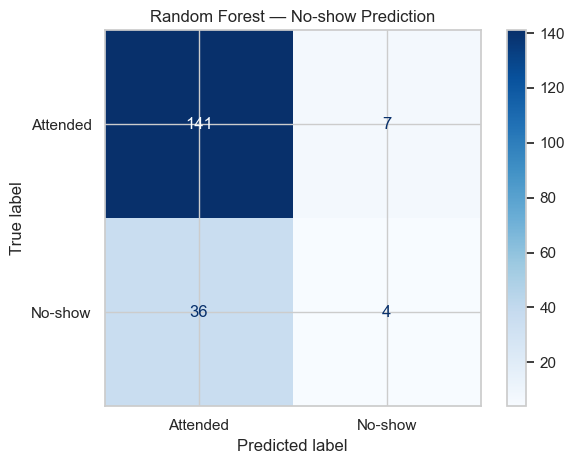

In [14]:
#Step 4: Train and evaluate a model
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Select features that are available and do not reveal the target
feature_columns = [
    "department",
    "booking_lead_days",
    "appointment_day",
    "appointment_month",
    "appointment_weekday",
    "is_weekend"
]

X = appointments_ml[feature_columns].copy()
y = appointments_ml["no_show"]

categorical_features = ["department"]
numeric_features = [c for c in feature_columns if c not in categorical_features]

# Preprocess missing values and categorical data
preprocessor = ColumnTransformer([
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features),

    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), numeric_features)
])

# Stratified split preserves the target-class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision (no-show):", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Recall (no-show):", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("F1-score (no-show):", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Attended", "No-show"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Attended", "No-show"],
    cmap="Blues"
)
plt.title("Random Forest — No-show Prediction")
plt.tight_layout()
plt.show()


Top 10 Important Features:
                            Feature  Importance
           numeric__appointment_day    0.294154
         numeric__appointment_month    0.218813
         numeric__booking_lead_days    0.193578
       numeric__appointment_weekday    0.140942
categorical__department_Orthopedics    0.028885
 categorical__department_Cardiology    0.027521
  categorical__department_Neurology    0.026226
 categorical__department_Pediatrics    0.025623
categorical__department_Dermatology    0.023092
                numeric__is_weekend    0.019560


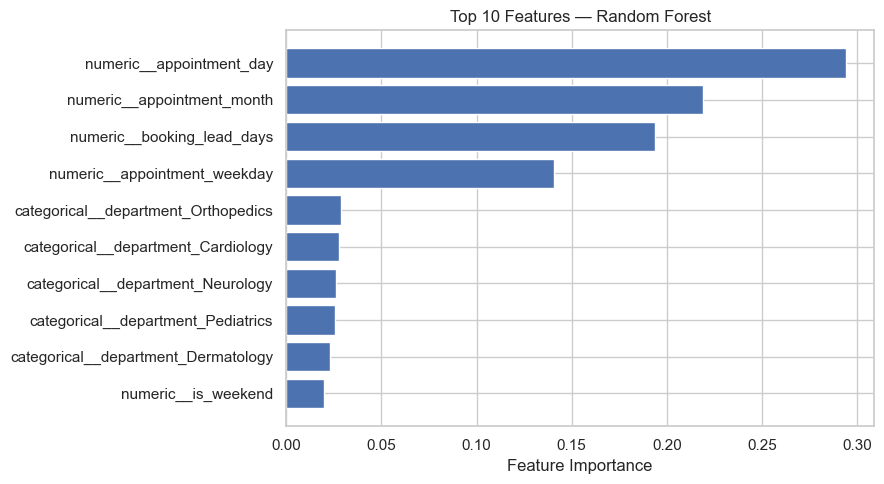

In [15]:

# Round 2: Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Get transformed feature names from preprocessing
preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()
importance = classifier.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print("Top 10 Important Features:")
print(feature_importance.head(10).to_string(index=False))

# Plot the top 10 features
top_features = feature_importance.head(10).sort_values("Importance")

plt.figure(figsize=(9, 5))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 10 Features — Random Forest")
plt.tight_layout()
plt.show()


In [16]:
#save the result
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save feature importance
feature_importance.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

# Save model evaluation metrics
evaluation_results = pd.DataFrame([{
    "model": "Random Forest",
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_no_show": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "recall_no_show": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "f1_no_show": f1_score(
        y_test, y_pred, zero_division=0
    )
}])

evaluation_results.to_csv(
    OUTPUT_DIR / "model_evaluation.csv",
    index=False
)

print("Saved:")
print(OUTPUT_DIR / "feature_importance.csv")
print(OUTPUT_DIR / "model_evaluation.csv")
print("\nEvaluation results:")
print(evaluation_results.round(4).to_string(index=False))


Saved:
output\feature_importance.csv
output\model_evaluation.csv

Evaluation results:
        model  accuracy  precision_no_show  recall_no_show  f1_no_show
Random Forest    0.7713             0.3636             0.1      0.1569


In [17]:

# ROUND 3 — STEP 1: INTELLIGENCE LAYER

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the existing cleaned appointment dataset
intelligence_df = appointments_clean.copy()

intelligence_df["status"] = (
    intelligence_df["status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

valid_df = intelligence_df.dropna(subset=["status"])
status_counts = valid_df["status"].value_counts()

total_records = len(intelligence_df)
attended = int(status_counts.get("attended", 0))
cancelled = int(status_counts.get("cancelled", 0))
no_show = int(status_counts.get("no-show", 0))
known_status = len(valid_df)

completed_or_no_show = attended + no_show

attendance_rate = (
    attended / completed_or_no_show * 100
    if completed_or_no_show else 0
)

no_show_rate = (
    no_show / completed_or_no_show * 100
    if completed_or_no_show else 0
)

cancellation_rate = (
    cancelled / known_status * 100
    if known_status else 0
)

kpis = pd.DataFrame({
    "Metric": [
        "Total appointment records",
        "Attended appointments",
        "Cancelled appointments",
        "No-show appointments",
        "Missing status records",
        "Attendance rate (%)",
        "No-show rate (%)",
        "Cancellation rate (%)"
    ],
    "Value": [
        total_records,
        attended,
        cancelled,
        no_show,
        total_records - known_status,
        round(attendance_rate, 2),
        round(no_show_rate, 2),
        round(cancellation_rate, 2)
    ]
})

print("CAREBRIDGE HOSPITAL — KPI REPORT")
print(kpis.to_string(index=False))

kpis.to_csv(OUTPUT_DIR / "round3_kpis.csv", index=False)
print("\nSaved to output/round3_kpis.csv")


CAREBRIDGE HOSPITAL — KPI REPORT
                   Metric   Value
Total appointment records 1200.00
    Attended appointments  742.00
   Cancelled appointments  258.00
     No-show appointments  198.00
   Missing status records    2.00
      Attendance rate (%)   78.94
         No-show rate (%)   21.06
    Cancellation rate (%)   21.54

Saved to output/round3_kpis.csv


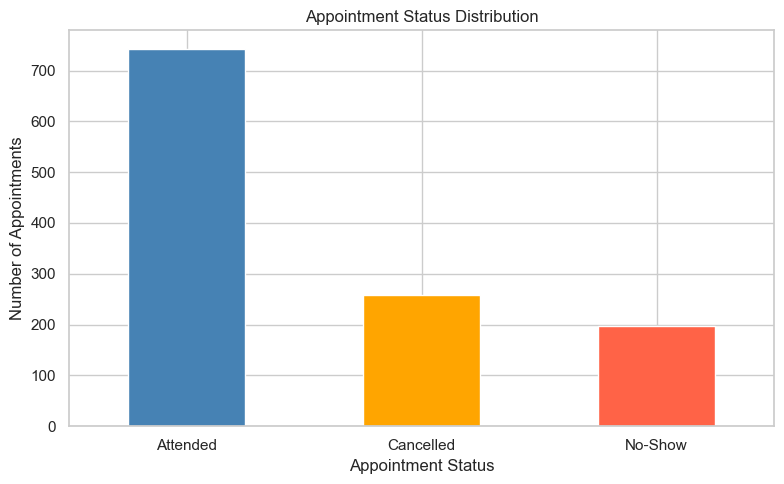

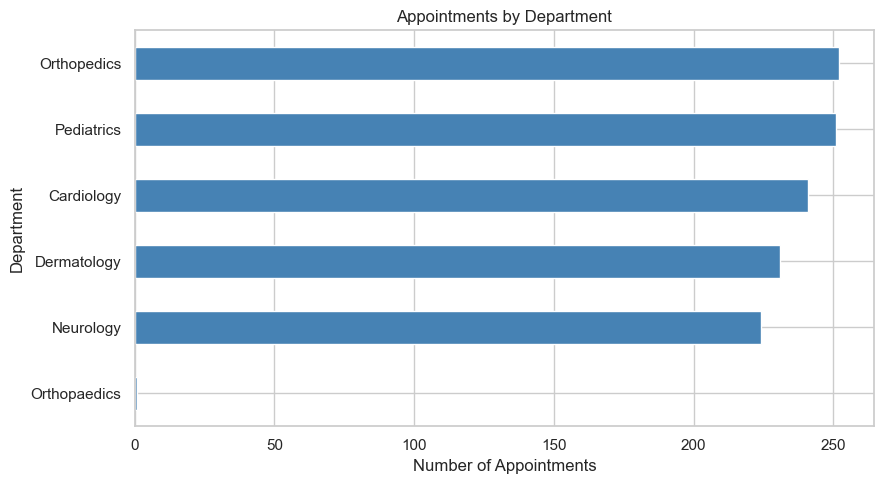

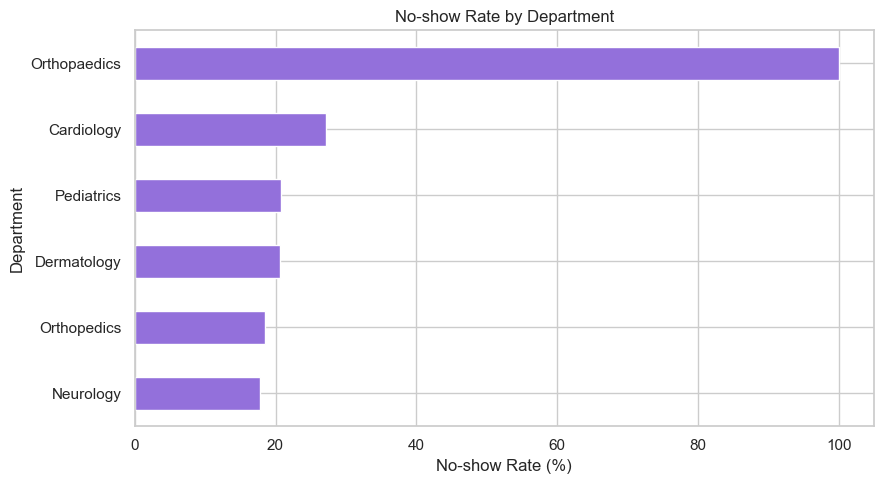

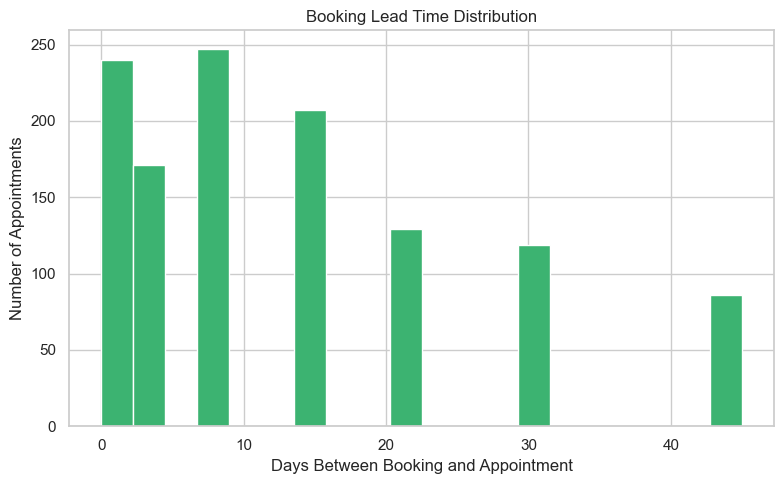


Visualization generation completed.
Charts saved in: E:\Hospital_Appointment_Insight\output\charts
Files: ['appointment_status.png', 'booking_lead_time.png', 'department_no_shows.png', 'department_no_show_rate.png', 'department_volume.png', 'waiting_days_distribution.png', 'weekday_no_show_rate.png']


In [18]:

# ROUND 3 — STEP 2: VISUALIZATION DASHBOARD

import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

CHART_DIR = Path("output") / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

df = appointments_clean.copy()
df["status"] = df["status"].astype("string").str.strip().str.title()

# 1. Appointment Status Distribution
status_counts = df["status"].value_counts()

plt.figure(figsize=(8, 5))
status_counts.plot(kind="bar", color=["steelblue", "orange", "tomato"])
plt.title("Appointment Status Distribution")
plt.xlabel("Appointment Status")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(CHART_DIR / "appointment_status.png", dpi=150)
plt.show()

# 2. Appointments by Department
if "department" in df.columns:
    dept_counts = df["department"].fillna("Unknown").value_counts()

    plt.figure(figsize=(9, 5))
    dept_counts.sort_values().plot(kind="barh", color="steelblue")
    plt.title("Appointments by Department")
    plt.xlabel("Number of Appointments")
    plt.ylabel("Department")
    plt.tight_layout()
    plt.savefig(CHART_DIR / "department_volume.png", dpi=150)
    plt.show()

# 3. No-show Rate by Department
if {"department", "status"}.issubset(df.columns):
    eligible = df[
        df["status"].isin(["Attended", "No-Show"])
    ].copy()

    if not eligible.empty:
        eligible["no_show_flag"] = (
            eligible["status"] == "No-Show"
        ).astype(int)

        rates = (
            eligible.groupby("department")["no_show_flag"]
            .mean().mul(100).sort_values()
        )

        plt.figure(figsize=(9, 5))
        rates.plot(kind="barh", color="mediumpurple")
        plt.title("No-show Rate by Department")
        plt.xlabel("No-show Rate (%)")
        plt.ylabel("Department")
        plt.tight_layout()
        plt.savefig(CHART_DIR / "department_no_show_rate.png", dpi=150)
        plt.show()

# 4. Booking Lead Time Distribution
date_cols = {"appointment_date", "booking_date"}

if date_cols.issubset(df.columns):
    df["appointment_date"] = pd.to_datetime(
        df["appointment_date"], errors="coerce"
    )
    df["booking_date"] = pd.to_datetime(
        df["booking_date"], errors="coerce"
    )

    df["booking_lead_days"] = (
        df["appointment_date"] - df["booking_date"]
    ).dt.days

    lead = df.loc[
        df["booking_lead_days"].between(0, 365),
        "booking_lead_days"
    ]

    if not lead.empty:
        plt.figure(figsize=(8, 5))
        lead.plot(kind="hist", bins=20, color="mediumseagreen")
        plt.title("Booking Lead Time Distribution")
        plt.xlabel("Days Between Booking and Appointment")
        plt.ylabel("Number of Appointments")
        plt.tight_layout()
        plt.savefig(CHART_DIR / "booking_lead_time.png", dpi=150)
        plt.show()

print("\nVisualization generation completed.")
print("Charts saved in:", CHART_DIR.resolve())
print("Files:", [p.name for p in CHART_DIR.glob("*.png")])


In [19]:

# ROUND 3 — STEP 3: INSIGHTS AND RECOMMENDATIONS

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = appointments_clean.copy()
df["status"] = df["status"].astype("string").str.strip().str.title()

# Analyze appointments with known status
valid = df.dropna(subset=["status"]).copy()

# Overall status summary
print("1. OVERALL APPOINTMENT INSIGHTS")
print("-" * 45)
print(valid["status"].value_counts().to_string())

# Department-level no-show analysis
eligible = valid[
    valid["status"].isin(["Attended", "No-Show"])
].copy()

if "department" in eligible.columns and not eligible.empty:
    eligible["no_show_flag"] = (
        eligible["status"] == "No-Show"
    ).astype(int)

    dept_summary = (
        eligible.groupby("department", dropna=False)
        .agg(
            eligible_appointments=("no_show_flag", "size"),
            no_show_count=("no_show_flag", "sum"),
            no_show_rate=("no_show_flag", "mean")
        )
        .reset_index()
    )

    dept_summary["no_show_rate"] = (
        dept_summary["no_show_rate"] * 100
    ).round(2)

    dept_summary = dept_summary.sort_values(
        "no_show_rate", ascending=False
    )

    print("\n2. NO-SHOW RATE BY DEPARTMENT")
    print(dept_summary.to_string(index=False))

    dept_summary.to_csv(
        OUTPUT_DIR / "department_insights.csv", index=False
    )

    largest = dept_summary.iloc[0]
    print(
        f"\nHighest observed department no-show rate: "
        f"{largest['department']} ({largest['no_show_rate']:.2f}%)"
    )

# Booking lead-time analysis
date_cols = {"appointment_date", "booking_date"}

if date_cols.issubset(df.columns):
    df["appointment_date"] = pd.to_datetime(
        df["appointment_date"], errors="coerce"
    )
    df["booking_date"] = pd.to_datetime(
        df["booking_date"], errors="coerce"
    )

    df["booking_lead_days"] = (
        df["appointment_date"] - df["booking_date"]
    ).dt.days

    valid_lead = df[
        df["booking_lead_days"].between(0, 365)
    ].copy()

    if not valid_lead.empty:
        valid_lead["lead_time_group"] = pd.cut(
            valid_lead["booking_lead_days"],
            bins=[-1, 7, 14, 30, 60, 90, 365],
            labels=["0–7", "8–14", "15–30", "31–60", "61–90", "91–365"]
        )

        lead_summary = (
            valid_lead.groupby(
                "lead_time_group", observed=False
            )
            .size()
            .rename("appointment_count")
            .reset_index()
        )

        print("\n3. BOOKING LEAD-TIME DISTRIBUTION")
        print(lead_summary.to_string(index=False))

        lead_summary.to_csv(
            OUTPUT_DIR / "booking_lead_time_insights.csv",
            index=False
        )

print("\nInsight reports saved in:", OUTPUT_DIR.resolve())


1. OVERALL APPOINTMENT INSIGHTS
---------------------------------------------
status
Attended     742
Cancelled    258
No-Show      198

2. NO-SHOW RATE BY DEPARTMENT
  department  eligible_appointments  no_show_count  no_show_rate
Orthopaedics                      1              1        100.00
  Cardiology                    191             52         27.23
  Pediatrics                    198             41         20.71
 Dermatology                    170             35         20.59
 Orthopedics                    200             37         18.50
   Neurology                    180             32         17.78

Highest observed department no-show rate: Orthopaedics (100.00%)

3. BOOKING LEAD-TIME DISTRIBUTION
lead_time_group  appointment_count
            0–7                658
           8–14                207
          15–30                248
          31–60                 86
          61–90                  0
         91–365                  0

Insight reports saved in: E:\Ho

In [20]:

from pathlib import Path

OUTPUT_DIR = Path("output")

print("ROUND 3 OUTPUT VERIFICATION")
print("=" * 40)

for file in [
    OUTPUT_DIR / "round3_kpis.csv",
    OUTPUT_DIR / "department_insights.csv",
    OUTPUT_DIR / "booking_lead_time_insights.csv",
    OUTPUT_DIR / "carebridge_dashboard.png"
]:
    print(f"{'[FOUND]' if file.exists() else '[NOT FOUND]'} {file}")

chart_folder = OUTPUT_DIR / "charts"
if chart_folder.exists():
    print("\nSaved chart images:")
    for image_file in sorted(chart_folder.glob("*.png")):
        print("-", image_file.name)


ROUND 3 OUTPUT VERIFICATION
[FOUND] output\round3_kpis.csv
[FOUND] output\department_insights.csv
[FOUND] output\booking_lead_time_insights.csv
[NOT FOUND] output\carebridge_dashboard.png

Saved chart images:
- appointment_status.png
- booking_lead_time.png
- department_no_show_rate.png
- department_no_shows.png
- department_volume.png
- waiting_days_distribution.png
- weekday_no_show_rate.png


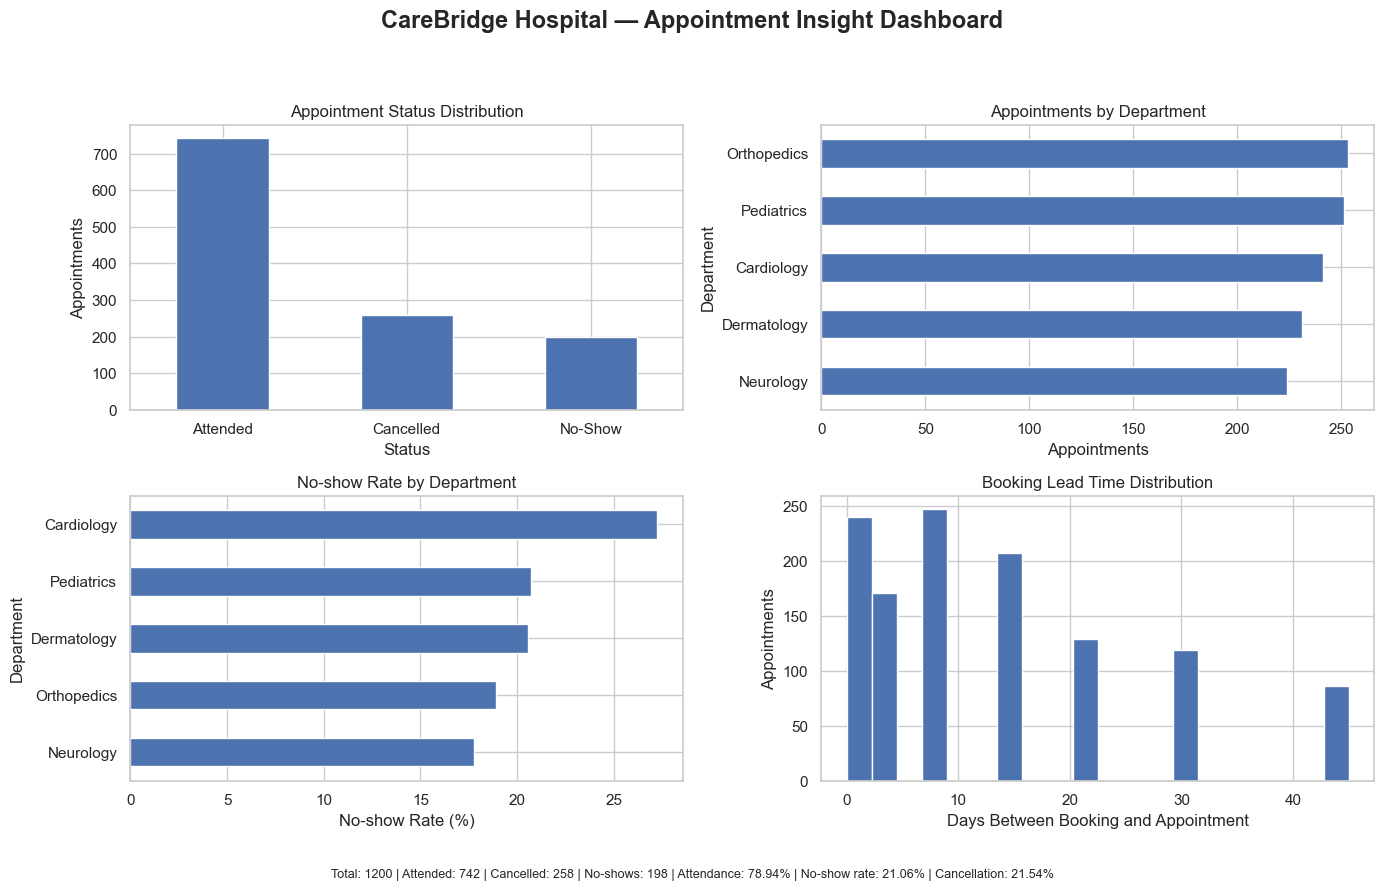

Dashboard saved: E:\Hospital_Appointment_Insight\output\carebridge_dashboard.png
File exists: True


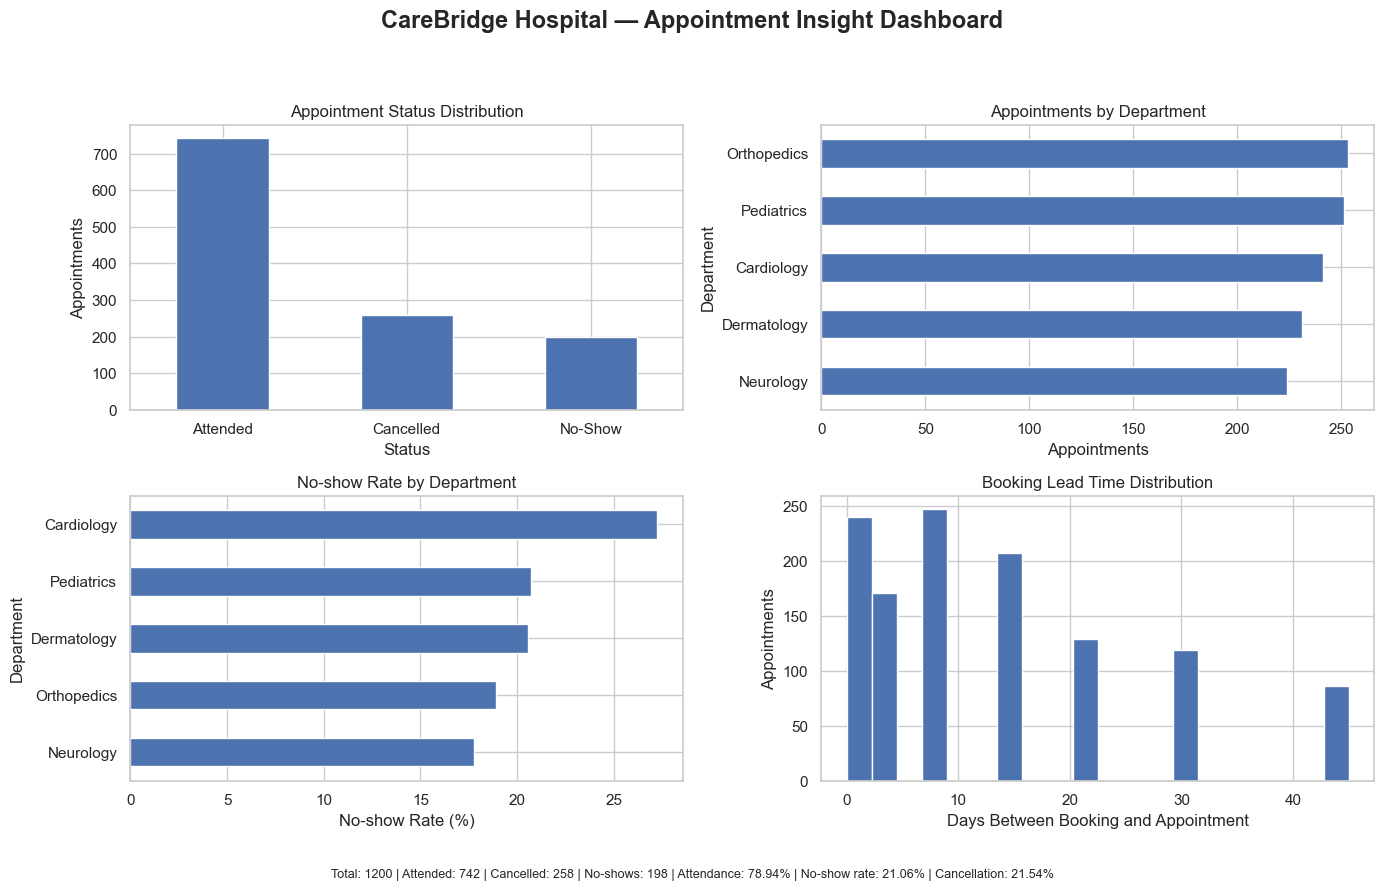

Dashboard saved: E:\Hospital_Appointment_Insight\output\carebridge_dashboard.png
File exists: True


In [21]:

# FIX: Generate the missing Round 3 dashboard

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = appointments_clean.copy()
df["status"] = df["status"].astype("string").str.strip().str.title()
df["department"] = df["department"].astype("string").str.strip().str.title()
df["department"] = df["department"].replace({
    "Orthopaedics": "Orthopedics"
})

valid = df.dropna(subset=["status"])
counts = valid["status"].value_counts()

attended = int(counts.get("Attended", 0))
cancelled = int(counts.get("Cancelled", 0))
no_show = int(counts.get("No-Show", 0))
total = len(df)

eligible_count = attended + no_show
attendance_rate = attended / eligible_count * 100 if eligible_count else 0
no_show_rate = no_show / eligible_count * 100 if eligible_count else 0
cancellation_rate = cancelled / len(valid) * 100 if len(valid) else 0

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(
    "CareBridge Hospital — Appointment Insight Dashboard",
    fontsize=17, fontweight="bold"
)

# Appointment status
counts.plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Appointment Status Distribution")
axes[0, 0].set_xlabel("Status")
axes[0, 0].set_ylabel("Appointments")
axes[0, 0].tick_params(axis="x", rotation=0)

# Department volume
dept_counts = df["department"].fillna("Unknown").value_counts()
dept_counts.sort_values().plot(kind="barh", ax=axes[0, 1])
axes[0, 1].set_title("Appointments by Department")
axes[0, 1].set_xlabel("Appointments")
axes[0, 1].set_ylabel("Department")

# Department no-show rate
eligible = df[df["status"].isin(["Attended", "No-Show"])].copy()
eligible["no_show_flag"] = (eligible["status"] == "No-Show").astype(int)
rates = eligible.groupby("department")["no_show_flag"].mean().mul(100)
rates.sort_values().plot(kind="barh", ax=axes[1, 0])
axes[1, 0].set_title("No-show Rate by Department")
axes[1, 0].set_xlabel("No-show Rate (%)")
axes[1, 0].set_ylabel("Department")

# Booking lead time
df["appointment_date"] = pd.to_datetime(df["appointment_date"], errors="coerce")
df["booking_date"] = pd.to_datetime(df["booking_date"], errors="coerce")
df["booking_lead_days"] = (
    df["appointment_date"] - df["booking_date"]
).dt.days

lead = df.loc[df["booking_lead_days"].between(0, 365), "booking_lead_days"]
if not lead.empty:
    lead.plot(kind="hist", bins=20, ax=axes[1, 1])
    axes[1, 1].set_title("Booking Lead Time Distribution")
    axes[1, 1].set_xlabel("Days Between Booking and Appointment")
    axes[1, 1].set_ylabel("Appointments")
else:
    axes[1, 1].text(0.5, 0.5, "No valid booking dates", ha="center")
    axes[1, 1].set_axis_off()

fig.text(
    0.5, 0.015,
    f"Total: {total} | Attended: {attended} | Cancelled: {cancelled} | "
    f"No-shows: {no_show} | Attendance: {attendance_rate:.2f}% | "
    f"No-show rate: {no_show_rate:.2f}% | Cancellation: {cancellation_rate:.2f}%",
    ha="center", fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 0.94])

dashboard_path = OUTPUT_DIR / "carebridge_dashboard.png"
plt.savefig(dashboard_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close()

print("Dashboard saved:", dashboard_path.resolve())
print("File exists:", dashboard_path.exists())

# FIX: Generate the missing Round 3 dashboard

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = appointments_clean.copy()
df["status"] = df["status"].astype("string").str.strip().str.title()
df["department"] = df["department"].astype("string").str.strip().str.title()
df["department"] = df["department"].replace({
    "Orthopaedics": "Orthopedics"
})

valid = df.dropna(subset=["status"])
counts = valid["status"].value_counts()

attended = int(counts.get("Attended", 0))
cancelled = int(counts.get("Cancelled", 0))
no_show = int(counts.get("No-Show", 0))
total = len(df)

eligible_count = attended + no_show
attendance_rate = attended / eligible_count * 100 if eligible_count else 0
no_show_rate = no_show / eligible_count * 100 if eligible_count else 0
cancellation_rate = cancelled / len(valid) * 100 if len(valid) else 0

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(
    "CareBridge Hospital — Appointment Insight Dashboard",
    fontsize=17, fontweight="bold"
)

# Appointment status
counts.plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Appointment Status Distribution")
axes[0, 0].set_xlabel("Status")
axes[0, 0].set_ylabel("Appointments")
axes[0, 0].tick_params(axis="x", rotation=0)

# Department volume
dept_counts = df["department"].fillna("Unknown").value_counts()
dept_counts.sort_values().plot(kind="barh", ax=axes[0, 1])
axes[0, 1].set_title("Appointments by Department")
axes[0, 1].set_xlabel("Appointments")
axes[0, 1].set_ylabel("Department")

# Department no-show rate
eligible = df[df["status"].isin(["Attended", "No-Show"])].copy()
eligible["no_show_flag"] = (eligible["status"] == "No-Show").astype(int)
rates = eligible.groupby("department")["no_show_flag"].mean().mul(100)
rates.sort_values().plot(kind="barh", ax=axes[1, 0])
axes[1, 0].set_title("No-show Rate by Department")
axes[1, 0].set_xlabel("No-show Rate (%)")
axes[1, 0].set_ylabel("Department")

# Booking lead time
df["appointment_date"] = pd.to_datetime(df["appointment_date"], errors="coerce")
df["booking_date"] = pd.to_datetime(df["booking_date"], errors="coerce")
df["booking_lead_days"] = (
    df["appointment_date"] - df["booking_date"]
).dt.days

lead = df.loc[df["booking_lead_days"].between(0, 365), "booking_lead_days"]
if not lead.empty:
    lead.plot(kind="hist", bins=20, ax=axes[1, 1])
    axes[1, 1].set_title("Booking Lead Time Distribution")
    axes[1, 1].set_xlabel("Days Between Booking and Appointment")
    axes[1, 1].set_ylabel("Appointments")
else:
    axes[1, 1].text(0.5, 0.5, "No valid booking dates", ha="center")
    axes[1, 1].set_axis_off()

fig.text(
    0.5, 0.015,
    f"Total: {total} | Attended: {attended} | Cancelled: {cancelled} | "
    f"No-shows: {no_show} | Attendance: {attendance_rate:.2f}% | "
    f"No-show rate: {no_show_rate:.2f}% | Cancellation: {cancellation_rate:.2f}%",
    ha="center", fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 0.94])

dashboard_path = OUTPUT_DIR / "carebridge_dashboard.png"
plt.savefig(dashboard_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close()

print("Dashboard saved:", dashboard_path.resolve())
print("File exists:", dashboard_path.exists())
